In [1]:
import argparse
import json
import time
from collections import defaultdict, deque

import numpy as np

WINDOW, THRESH, MIN_HISTORY = 20, 4.0, 10

In [2]:
class StreamDetector:
    def __init__(self):
        self.hist = defaultdict(lambda: deque(maxlen=WINDOW))

    def process(self, node, value):
        h = self.hist[node]
        is_anom, z = False, 0.0
        if len(h) >= MIN_HISTORY:
            x = np.arange(len(h))
            slope, icpt = np.polyfit(x, h, 1)
            resid = np.array(h) - (slope * x + icpt)
            sd = max(resid.std(), 1e-6)
            pred = slope * len(h) + icpt
            z = (value - pred) / sd
            is_anom = abs(z) > THRESH
            h.append(pred if is_anom else value)
        else:
            h.append(value)
        return is_anom, z

In [3]:
def local_stream(n=400, seed=7):
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    base = 18 + 4 * np.sin(2 * np.pi * t / 120)           # slow daily-like cycle
    vals = base + rng.normal(0, 0.4, n)
    for i in rng.choice(np.arange(40, n), 8, replace=False):  # inject faults
        vals[i] += rng.choice([-1, 1]) * rng.uniform(6, 10)
    for i, v in enumerate(vals):
        yield {"node": "node-001", "temperature": float(v), "i": i}

In [4]:
def kinesis_stream(stream, region):
    import boto3
    kin = boto3.client("kinesis", region_name=region)
    for shard in kin.describe_stream(StreamName=stream)["StreamDescription"]["Shards"]:
        it = kin.get_shard_iterator(StreamName=stream, ShardId=shard["ShardId"],
                                    ShardIteratorType="LATEST")["ShardIterator"]
        while it:
            out = kin.get_records(ShardIterator=it, Limit=100)
            for r in out["Records"]:
                yield json.loads(r["Data"])
            it = out["NextShardIterator"]
            time.sleep(1)

   # node           temp       z  status
  75 node-001       6.68  -22.35  ANOMALY
 103 node-001      15.79    4.93  ANOMALY
 140 node-001      14.56  -17.10  ANOMALY
 194 node-001       7.33  -27.11  ANOMALY
 205 node-001      22.60   23.07  ANOMALY
 248 node-001      13.29  -16.67  ANOMALY
 277 node-001      20.69   -4.86  ANOMALY
 293 node-001      10.89  -25.65  ANOMALY
 324 node-001      22.63   23.55  ANOMALY
 327 node-001       4.58  -29.25  ANOMALY

Processed 400 readings, flagged 10 anomalies.


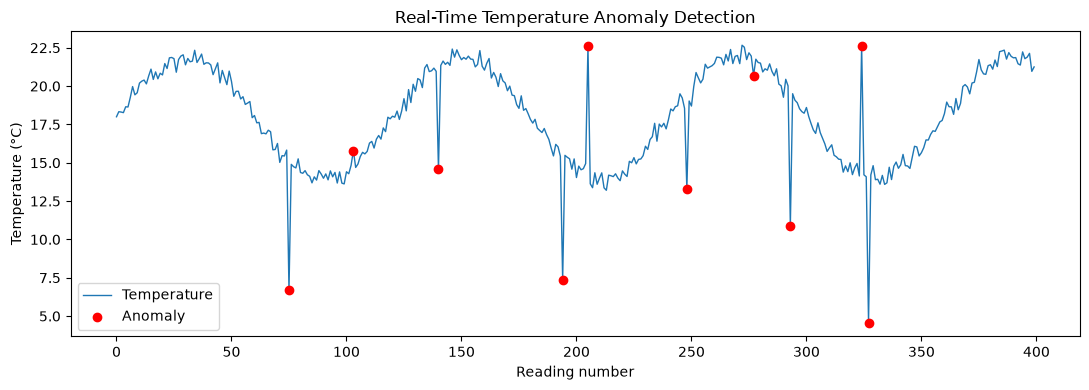

In [6]:

# Configure the stream source here
mode = "local"  # "local" or "kinesis"
stream_name = "array-of-things"
region = "us-east-2"

# Select data source
source = (
    local_stream()
    if mode == "local"
    else kinesis_stream(stream_name, region)
)

det = StreamDetector()
xs, ys, flagged = [], [], []

print(f"{'#':>4} {'node':10} {'temp':>8} {'z':>7}  status")

for idx, rec in enumerate(source):
    anom, z = det.process(rec["node"], rec["temperature"])

    xs.append(idx)
    ys.append(rec["temperature"])

    if anom:
        flagged.append(idx)
        print(
            f"{idx:>4} {rec['node']:10} "
            f"{rec['temperature']:8.2f} {z:7.2f}  ANOMALY"
        )

    if mode == "local" and idx + 1 >= 400:
        break

print(
    f"\nProcessed {len(xs)} readings, "
    f"flagged {len(flagged)} anomalies."
)

# Plot results inline in Jupyter
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))
plt.plot(xs, ys, linewidth=1, label="Temperature")

plt.scatter(
    flagged,
    [ys[i] for i in flagged],
    color="red",
    zorder=3,
    label="Anomaly"
)

plt.xlabel("Reading number")
plt.ylabel("Temperature (°C)")
plt.title("Real-Time Temperature Anomaly Detection")
plt.legend()
plt.tight_layout()
plt.show()
